# Zero-shot

Câu lạc bộ cần gắn nhãn ảnh “bàn”, “bảng”, “máy tính” nhưng chưa có bộ ảnh đã gán nhãn để học head. Ta đã có một model học ghép ảnh với mô tả. Có thể đưa tên lớp vào model rồi so ảnh với các tên đó không? Một yêu cầu khác là xếp hạng hai cách hoàn thành câu hỏi thuật toán bằng model ngôn ngữ. Hai việc đều có thể làm mà chưa huấn luyện trên nhãn mới, nhưng dùng hai loại điểm khác nhau. Buổi này học zero-shot bằng CLIP và chấm chuỗi bằng log-probability, đồng thời kiểm vì sao một số điểm cao chưa phải bằng chứng đáp án đúng.

> **Mục tiêu sau bài này**
>
> - Phân biệt zero-shot, few-shot và fine-tuning theo cách mỗi cách dùng ví dụ có nhãn của nhiệm vụ mới; zero-shot không có nghĩa model chưa từng học.
> - Dựng classifier CLIP từ embedding ảnh và mô tả lớp, kiểm chuẩn hóa và shape.
> - Tính log-probability, điểm trung bình theo token và perplexity bằng tay.
> - Phân biệt điểm tương đồng, xác suất trên tập lớp ứng viên và chất lượng đã được validation đo.

## Zero-shot chuyển điều gì từ việc học trước?

Trong supervised classification thông thường, ta học các nhãn như 0, 1, 2 từ nhiều input đã gán nhãn. Zero-shot dùng kiến thức học trước để xử lý một nhiệm vụ mới mà không cập nhật trọng số từ ví dụ có nhãn của nhiệm vụ đó. Model vẫn đã học rất nhiều dữ liệu trước đây. Nếu dữ liệu mới giống dữ liệu học trước, nó có thể làm tốt; nếu khác ngôn ngữ, khác kiểu ảnh hoặc có khái niệm chưa học, kết quả có thể kém.

Giữa zero-shot và fine-tuning còn few-shot: đặt vài ví dụ có nhãn ngay trong prompt của model ngôn ngữ rồi để model hoàn thành ví dụ mới (in-context learning). Trọng số vẫn giữ nguyên; các ví dụ chỉ là phần ngữ cảnh được đọc lúc dự đoán. Vì đã dùng nhãn của nhiệm vụ, kết quả few-shot không được báo là zero-shot. Ngược lại, prompt chỉ có câu hỏi và lời dặn “hãy suy nghĩ từng bước”, không kèm ví dụ nào, vẫn là zero-shot. Fine-tuning (bài 4.3) thì dùng chính các ví dụ ấy để cập nhật trọng số.



CLIP có một image encoder và một text encoder được học để đưa ảnh cùng mô tả phù hợp đến gần nhau. Trong một batch cặp ảnh–chữ, ma trận tương đồng có các cặp đúng trên đường chéo. Mục tiêu contrastive khuyến khích đường chéo cao hơn các cặp không khớp, theo cả chiều ảnh tìm chữ và chữ tìm ảnh. Mọi ô ngoài đường chéo đều được coi là cặp không khớp, dù đôi khi hai ảnh trong batch có nội dung rất gần nhau; đó là giới hạn của cách dựng tín hiệu học.



Khi phân loại nhãn mới, ta không dùng một head học từ ảnh của bài mới. Ta tạo một mô tả cho mỗi lớp, lấy text embedding, rồi so image embedding với các vector lớp. Hai encoder phải thuộc cùng model được học để chia sẻ không gian; lấy vector của một model ảnh và một model chữ tùy ý rồi nhân vô hướng không có cơ sở chỉ vì cùng số chiều.

**Hỏi nhanh.** Một batch có hai ảnh mèo khác nhau, và cả hai đều đi với caption “a photo of a cat”. Trong contrastive loss, ô (ảnh mèo 1, caption của ảnh mèo 2) được xử lý thế nào?

- A. Được coi là cặp đúng thứ hai của ảnh mèo 1
- B. Bị bỏ khỏi loss, vì hai caption trùng nhau
- C. Vẫn là một cặp không khớp trong loss
- D. Không ảnh hưởng gì, vì loss chỉ đọc đường chéo

<details><summary>Đáp án</summary>

C. Vẫn là một cặp không khớp trong loss

Nhãn của contrastive loss chỉ là chỉ số của cặp trong batch: hàng $i$ phải chọn cột $i$, mọi ô khác đều là cặp không khớp, và loss không đọc nội dung caption để miễn trừ. Các ô ngoài đường chéo nằm trong mẫu số của softmax, nên vẫn có ảnh hưởng. Ở đây hai caption có cùng embedding, nên hai logit trên hàng bằng nhau: xác suất của cặp đúng không vượt quá $1/2$, và loss của hàng không xuống dưới $\ln 2$. Đó chính là giới hạn của cách dựng tín hiệu học này.

</details>

**Hỏi nhanh.** Một đội lấy embedding ảnh 512 chiều từ một ResNet đã học trên ImageNet, và embedding 512 chiều của tên lớp từ một text encoder khác, chuẩn hóa cả hai, rồi gán nhãn bằng cosine. Cách làm này thế nào?

- A. Dùng được, vì cùng số chiều và đã chuẩn hóa
- B. Không có cơ sở, vì hai encoder chưa học chung một không gian
- C. Dùng được, nếu nhân thêm logit scale của CLIP
- D. Dùng được, nếu prompt mô tả đủ chi tiết

<details><summary>Đáp án</summary>

B. Không có cơ sở, vì hai encoder chưa học chung một không gian

Cùng số chiều chỉ đủ để phép nhân chạy được. Tọa độ thứ $j$ của hai encoder không mang cùng nghĩa, vì chúng chưa từng được học trên các cặp ảnh và chữ. Nhân một scale dương không đổi thứ hạng. Prompt chi tiết hơn chỉ đổi vector chữ trong một không gian vẫn không khớp với ảnh. Muốn nối hai encoder có sẵn thì phải học thêm một phép chiếu từ dữ liệu cặp ảnh và chữ.

</details>

## Từ tên lớp đến một classifier

Giả sử $\mathbf{u}$ là embedding ảnh và $\mathbf{v}_k$ là embedding mô tả lớp $k$, đều chuẩn hóa độ dài 1. Điểm lớp là

$$\ell_k=s\,\mathbf{u}^\top\mathbf{v}_k,\qquad \hat y=\argmax_k\ell_k.$$

$s>0$ là logit scale; có thể viết $s=1/\tau$ với $\tau$ gọi là temperature. Trong CLIP, $\tau$ được học cùng hai encoder: bài báo gốc khởi tạo $\tau=0.07$ và chặn để $s$ không vượt 100. Gọi logits API của model là dùng đúng scale đã học; ví dụ ở mục sau chọn $s=5$ để số dễ tính tay. Scale dương không đổi argmax của một tập embedding cố định, nhưng đổi mức tập trung của softmax: $s$ lớn làm phân phối nhọn, $s$ nhỏ làm nó phẳng. Với $s = 100$, cosine 0.30, 0.28, 0.10 thành logits 30, 28, 10, nên lớp đầu nhận khoảng $1/(1 + e^{-2}) \approx 0.88$: chênh 0.02 cosine đã thành chênh lớn về xác suất.

Với $B$ ảnh, $K$ lớp và embedding $D$ chiều, $U$ có shape `(B,D)`, $V$ có shape `(K,D)`, còn `U @ V.T` có shape `(B,K)`. Mỗi hàng là một ảnh, mỗi cột là một lớp. Đây là phép nhân ma trận quen thuộc từ linear probe, nhưng vector của lớp đến từ text encoder thay vì được học từ nhãn của bài mới. Cùng ý tưởng cho phép phát hiện vật thể theo tên lớp chưa từng có nhãn hộp: so embedding của từng vùng ảnh với text embedding của tên lớp (open-vocabulary detection).

**Hỏi nhanh.** `U` có shape `(8, 512)`, `V` có shape `(3, 512)`. Điểm của tám ảnh với ba lớp có shape gì?

- A. `(8, 3)`
- B. `(3, 8)`
- C. `(8, 512)`
- D. `(512, 512)`

<details><summary>Đáp án</summary>

A. `(8, 3)`

`U @ V.T` nhân `(8, 512)` với `(512, 3)`, và mỗi hàng là một ảnh. `(3, 8)` là kết quả của `V @ U.T`: cùng các con số nhưng hàng là lớp, nên lấy argmax theo hàng sẽ chọn sai trục. `(8, 512)` là shape của chính `U`. `(512, 512)` có dạng `U.T @ U`, trộn các ảnh với nhau chứ không so ảnh với lớp.

</details>

**Hỏi nhanh.** Nhân mọi logits với một scale dương lớn hơn, giữ nguyên embedding và tập lớp. Thứ gì chắc chắn giữ nguyên?

- A. Mọi xác suất softmax
- B. Cross-entropy của mọi mẫu
- C. Khoảng cách giữa hai logit lớn nhất
- D. Chỉ số của logit lớn nhất

<details><summary>Đáp án</summary>

D. Chỉ số của logit lớn nhất

Nhân với một số dương thì giữ nguyên thứ tự, nên argmax giữ nguyên. Khoảng cách giữa các logit giãn ra theo scale, nên softmax nhọn hơn và cross-entropy đổi theo. Chẳng hạn, với mẫu có lớp đúng đạt logit lớn nhất, cross-entropy giảm.

</details>

## Ví dụ tính tay và kiểm bằng NumPy

Ta dùng embedding hai chiều tự đặt để nhìn rõ hình học; embedding của CLIP có hàng trăm chiều nhưng phép tính giống hệt. Ảnh có vector $(0.8,0.6)$, hai mô tả lớp có vector $(1,0)$ và $(0,1)$. Cả ba đều dài 1. Cosine lần lượt là 0.8 và 0.6. Với scale 5, logits là 4 và 3; softmax trên hai lớp cho lớp đầu $e^4/(e^4+e^3)=1/(1+e^{-1})\approx0.7311$. Code dưới đây thêm ảnh thứ hai, ảnh thứ ba và lớp thứ ba để có đủ một ma trận.

In [ ]:
import numpy as np

def normalize(matrix):
    norm = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norm, 1e-12)

def softmax(matrix):
    shifted = matrix - matrix.max(axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / exp_values.sum(axis=1, keepdims=True)

images = normalize(np.array([[.8, .6], [.6, .8], [-1., 0.]]))
texts = normalize(np.array([[1., 0.], [0., 1.], [-1., 0.]]))
class_names = ["ban", "bang", "may_tinh"]
scale = 5.0
scores = images @ texts.T
logits = scale * scores
probabilities = softmax(logits)
print("shape logits:", logits.shape)
print("cosine:", scores.round(2))
print("nhan:", [class_names[k] for k in logits.argmax(axis=1)])
print("softmax hang dau:", probabilities[0].round(4).tolist())
print("chi hai lop:", round(float(softmax(logits[:1, :2])[0, 0]), 4))

shape logits: (3, 3)
cosine: [[ 0.8  0.6 -0.8]
 [ 0.6  0.8 -0.6]
 [-1.   0.   1. ]]
nhan: ['ban', 'bang', 'may_tinh']
softmax hang dau: [0.7309, 0.2689, 0.0002]
chi hai lop: 0.7311


Hàng đầu có thêm lớp thứ ba với cosine -0.8, nên xác suất của lớp đầu trên ba lớp (0.7309) hơi thấp hơn con số tính tay trên hai lớp (0.7311). Ba nhãn in ra khớp với hướng gần nhất của từng ảnh: argmax đang làm đúng phép hình học đã đặt. Accuracy chỉ có nghĩa khi có ảnh thật và nhãn thật; recipe cuối bài chấm nó trên validation.



**Hỏi nhanh.** Quên chuẩn hóa `texts`, và vector của lớp thứ hai là $(0, 3)$ thay vì $(0, 1)$. Ảnh $(0.8, 0.6)$ được gán vào lớp nào?

- A. Lớp thứ hai, vì tích vô hướng thành 1.8
- B. Lớp thứ hai, vì cosine thành 1.8
- C. Lớp đầu, vì cosine với lớp đầu vẫn là 0.8
- D. Lớp đầu, vì nhân một hằng số không đổi argmax

<details><summary>Đáp án</summary>

A. Lớp thứ hai, vì tích vô hướng thành 1.8

Code tính `images @ texts.T`, tức tích vô hướng, chỉ bằng cosine khi cả hai vector dài 1. Lớp thứ hai có tích $0.6\times 3 = 1.8 > 0.8$ nên thắng, dù theo cosine thì vẫn chọn lớp đầu; cosine không bao giờ vượt quá 1. Nhân cùng một scale cho mọi logit thì giữ argmax, nhưng ở đây chỉ một lớp bị nhân 3: lớp ấy được lợi chỉ vì vector dài, chứ không phải vì gần ảnh hơn.

</details>

Ta kiểm phép nhân bằng vòng lặp, rồi tính contrastive loss của ba cặp trên đường chéo, đúng đại lượng mà pretraining CLIP tối ưu trên mỗi batch: hàng $i$ (ảnh) phải chọn cột $i$ (mô tả) và ngược lại.

In [ ]:
reference = np.zeros_like(scores)
for i in range(len(images)):
    for k in range(len(texts)):
        reference[i, k] = sum(images[i, j] * texts[k, j] for j in range(2))
image_to_text = -np.log(np.diag(softmax(logits))).mean()
text_to_image = -np.log(np.diag(softmax(logits.T))).mean()
contrastive_loss = (image_to_text + text_to_image) / 2
print("dot khop vong lap:", np.allclose(scores, reference))
print("image-to-text loss:", round(float(image_to_text), 4))
print("text-to-image loss:", round(float(text_to_image), 4))
print("loss trung binh:", round(float(contrastive_loss), 4))

dot khop vong lap: True
image-to-text loss: 0.2114
text-to-image loss: 0.2135
loss trung binh: 0.2124


Dòng `True` xác nhận `images @ texts.T` đúng là tích vô hướng từng cặp (hàng ảnh, cột lớp). Hai loss dùng cùng logits nhưng softmax theo hai chiều khác nhau: theo hàng là ảnh tìm chữ, theo cột là chữ tìm ảnh. Chúng thường không bằng nhau vì phân bố trên hàng và trên cột khác nhau. Loss pretraining nhỏ cũng chưa nói accuracy trên nhãn của bài mới cao: hai đại lượng đo hai việc khác nhau.



## Tên lớp, prompt và tập ứng viên có ảnh hưởng

Text encoder đọc cả chuỗi, không chỉ một số nguyên biểu thị lớp. “A photo of a desk” và “desk” có thể cho vector khác nhau. Prompt nên mô tả đúng loại input và phân biệt được các lớp. Một từ có nhiều nghĩa, hoặc một nhãn quá ngắn, có thể không biểu đạt mục tiêu. Với model chủ yếu học tiếng Anh, phải kiểm riêng ngôn ngữ muốn dùng; không giả định chất lượng tiếng Việt bằng tiếng Anh.

Có thể dùng nhiều template cho mỗi lớp, chuẩn hóa từng text embedding, trung bình rồi chuẩn hóa vector lớp lần nữa. Mục tiêu giảm phụ thuộc một cách diễn đạt. Đó là một lựa chọn cần ghi rõ. Nếu chọn template theo điểm validation có nhãn, ta đã dùng nhãn nhiệm vụ để chọn phương pháp, dù không train trọng số; phải khai báo điều ấy nếu benchmark yêu cầu zero-shot theo nghĩa nghiêm ngặt.

**Hỏi nhanh.** Một đội thử 20 template, giữ template có accuracy cao nhất trên 100 ảnh validation có nhãn, rồi báo chính con số ấy là “accuracy zero-shot”. Báo như vậy có ổn không?

- A. Ổn, vì không trọng số nào được cập nhật
- B. Ổn, nếu cả 20 template đều do người viết tay
- C. Không ổn, con số quá lạc quan, vì nhãn đã được dùng để chọn template
- D. Không ổn, vì zero-shot không được dùng nhiều template

<details><summary>Đáp án</summary>

C. Không ổn, con số quá lạc quan, vì nhãn đã được dùng để chọn template

Chọn cái tốt nhất trong 20 trên đúng 100 ảnh, rồi báo điểm trên chính 100 ảnh ấy, là một ước lượng quá lạc quan, giống chọn seed đẹp nhất (bài 1.7). Nhãn cũng đã tham gia chọn phương pháp, nên phải khai báo điều đó, và báo điểm trên một tập riêng chưa dùng để chọn. Không cập nhật trọng số không có nghĩa là không dùng nhãn, và ai viết template cũng không thay đổi được điều đó. Lấy trung bình nhiều template thì vẫn hợp lệ, nếu cách lấy trung bình được cố định từ trước.

</details>

Softmax chỉ chuẩn hóa trên các lớp được đưa vào. Nó không cho biết ảnh có thuộc một trong các lớp đó hay không. Ta thêm một lớp thứ tư có vector trùng hướng với ảnh đầu, giữ nguyên ảnh và ba lớp cũ.

In [ ]:
new_texts = np.vstack([texts, normalize(np.array([[.8, .6]]))])
new_logits = scale * images[:1] @ new_texts.T
new_probabilities = softmax(new_logits)
print("xac suat lop cu truoc:", round(float(probabilities[0, 0]), 4))
print("xac suat lop cu sau:", round(float(new_probabilities[0, 0]), 4))
print("chi so thang sau:", int(new_logits.argmax(axis=1)[0]))

xac suat lop cu truoc: 0.7309
xac suat lop cu sau: 0.2447
chi so thang sau: 3


Ảnh và vector lớp cũ không thay đổi nhưng xác suất lớp cũ giảm, vì mẫu số có thêm ứng viên. Vì vậy một giá trị như 0.9 không mặc nhiên là độ tin cậy đã hiệu chuẩn cho thế giới mở. Nếu cần lớp “khác”, phải có quy trình và validation kiểm ngưỡng hoặc phương pháp phát hiện ngoài miền; thêm từ “other” không tự giải quyết vấn đề.



**Hỏi nhanh.** Ảnh chụp một cái ghế, nhưng tập lớp chỉ có bàn, bảng và máy tính. Softmax cho “bàn” 0.92. Hiểu con số này thế nào?

- A. Bàn là lớp khớp nhất trong ba lớp đã cho
- B. Ảnh có 92% khả năng là một cái bàn
- C. Ảnh là cái bàn, vì 0.92 vượt ngưỡng 0.5
- D. Model hỏng, vì ảnh lạ thì softmax phải nhỏ

<details><summary>Đáp án</summary>

A. Bàn là lớp khớp nhất trong ba lớp đã cho

Softmax luôn chia đủ 1 cho các lớp được đưa vào. Ghế gần bàn hơn là gần bảng hay máy tính, nên “bàn” nhận gần hết xác suất. Không có lớp “ghế” thì model không thể trả lời “ghế”. 0.92 là xác suất có điều kiện trên một tập đóng, không phải xác suất để ảnh là cái bàn trong thế giới mở. Ngưỡng 0.5 hay 0.9 cũng chỉ có nghĩa sau khi validation có cả những ảnh nằm ngoài tập lớp.

</details>

## Dùng model ngôn ngữ để chấm cách hoàn thành

Một causal language model dự đoán token tiếp theo từ các token trước. Cho prompt $c$ và một ứng viên gồm $m$ token $t_1,\dots,t_m$, xác suất chuỗi phân tích thành tích các xác suất có điều kiện. Tích nhiều số nhỏ dễ underflow nên dùng log:

$$\log p(t_1,\dots,t_m\mid c)=\sum_{j=1}^m\log p(t_j\mid c,t_{<j}).$$

Ta có thể xếp hạng cách hoàn thành câu bằng tổng này. Nhưng chuỗi dài thường tích thêm nhiều số không quá 1 nên bị phạt độ dài. Điểm trung bình mỗi token là tổng chia $m$, đổi câu hỏi thành độ hợp lý trung bình mỗi token. Hai tiêu chí có thể xếp hạng khác nhau; không có lựa chọn đúng cho mọi nhiệm vụ. Phải dùng đúng giao thức bài và validation để chọn.

Khi dùng nhãn để phân loại, giữ cùng prompt, quy tắc khoảng trắng, tokenizer và phần token cần chấm. Chỉ chấm token của ứng viên; nếu tính cả prompt, một prompt dài dễ lấn át điểm. Tên lớp có số token và tần suất khác nhau nên độ phổ biến của từ cũng ảnh hưởng điểm, không chỉ sự liên quan đến input. Một cách kiểm là chấm các nhãn với một input trung tính, ví dụ chuỗi rỗng hoặc “N/A”: nhãn nào đã thắng sẵn khi chưa có nội dung thì điểm đang mang độ lệch của nhãn. Trừ điểm nền này là một hiệu chỉnh thường dùng, nhưng hiệu quả của nó vẫn phải được validation xác nhận.

**Hỏi nhanh.** Hai ứng viên dùng chung một prompt 40 token. Một bạn lỡ cộng log-prob của 40 token prompt vào điểm của mỗi ứng viên. Thứ hạng theo tổng log và theo trung bình log có thể đổi không?

- A. Theo tổng có thể đổi, theo trung bình thì không
- B. Theo tổng không đổi, theo trung bình thì có thể đổi
- C. Cả hai đều không đổi
- D. Cả hai đều có thể đổi

<details><summary>Đáp án</summary>

B. Theo tổng không đổi, theo trung bình thì có thể đổi

Trong causal model, token của prompt chỉ nhìn các token đứng trước nó, nên log-prob của prompt là cùng một số $L_c$ cho mọi ứng viên. Tổng thành $L_c + S_k$, tức cộng cùng một hằng số, nên thứ hạng giữ nguyên. Trung bình thành $(L_c + S_k)/(40 + m_k)$, và hằng số lớn ấy bị chia cho những độ dài khác nhau. Ví dụ $L_c = -80$; A có 2 token, tổng $-1$; B có 4 token, tổng $-3$. Chỉ chấm ứng viên thì trung bình của A là $-0.5$, thắng B với $-0.75$. Cộng cả prompt thì A được $-81/42 \approx -1.929$, B được $-83/44 \approx -1.886$, nên B thắng.

</details>

## Ví dụ tính tay: tổng log và trung bình log

Hai đường token giả định có xác suất có điều kiện A: $(0.6,0.8)$ và B: $(0.4,0.95,0.95)$. Ở bước đầu chỉ có hai token khả dĩ nên $0.6+0.4=1$; các số sau là xác suất có điều kiện trong ngữ cảnh riêng của từng đường. Bảng tự đặt này cho phép tính tay toàn bộ; với model thật, mỗi số được đọc từ softmax của logits tại vị trí tương ứng.

Xác suất chuỗi A là $0.48$, chuỗi B là $0.361$, nên tổng log chọn A. Trung bình log chia 2 hoặc 3 có thể chọn B: chuỗi B dài hơn nhưng các bước sau rất dễ đoán.

In [ ]:
conditional = {
    "A": np.array([0.6, 0.8]),
    "B": np.array([0.4, 0.95, 0.95]),
}
sum_scores, mean_scores = {}, {}
for name, token_probabilities in conditional.items():
    sum_log = np.log(token_probabilities).sum()
    mean_log = sum_log / len(token_probabilities)
    perplexity = np.exp(-mean_log)
    sum_scores[name], mean_scores[name] = sum_log, mean_log
    print(name, "prob =", round(float(token_probabilities.prod()), 4),
          "sum log =", round(float(sum_log), 4),
          "mean log =", round(float(mean_log), 4),
          "PPL =", round(float(perplexity), 4))
print("tong log chon:", max(sum_scores, key=sum_scores.get))
print("mean log chon:", max(mean_scores, key=mean_scores.get))

A prob = 0.48 sum log = -0.734 mean log = -0.367 PPL = 1.4434
B prob = 0.361 sum log = -1.0189 mean log = -0.3396 PPL = 1.4044
tong log chon: A
mean log chon: B


Nhìn hai dòng chọn cuối để thấy đổi cách chuẩn hóa là đổi thứ hạng. Perplexity (PPL) bằng $\exp(-\text{mean log})$; càng thấp thì các token càng dễ được model đoán theo ngữ cảnh. Nó không đo tính đúng của lời giải thuật toán. Một câu sai nhưng quen thuộc có thể có xác suất cao; muốn kiểm thuật toán vẫn cần lập luận hoặc chạy test.



**Hỏi nhanh.** Nối thêm vào cuối B một token có xác suất có điều kiện 0.99. Tổng log và trung bình log của B thay đổi thế nào?

- A. Tổng tăng, trung bình tăng
- B. Tổng tăng, trung bình giảm
- C. Tổng giảm, trung bình tăng
- D. Tổng giảm, trung bình giảm

<details><summary>Đáp án</summary>

C. Tổng giảm, trung bình tăng

$\log 0.99 \approx -0.01 < 0$, nên tổng giảm từ $-1.0189$ xuống $-1.0289$. Trung bình thành $-1.0289/4 \approx -0.2572$, cao hơn $-0.3396$, vì token mới dễ hơn mức trung bình cũ. Tổng log không bao giờ tăng khi nối thêm token. Trung bình thì thưởng cho một cái đuôi dễ đoán, nên có thể ưu ái những ứng viên dài dòng.

</details>

## Perplexity cần cùng giao thức

Nếu mỗi token có xác suất 0.5, mean negative log bằng $-\log0.5$, nên perplexity bằng 2 dù có hai hay ba token. Ta đối chiếu với căn bậc $m$ của nghịch đảo xác suất chuỗi:

In [ ]:
for length in [2, 3]:
    token_probabilities = np.full(length, 0.5)
    from_log = np.exp(-np.log(token_probabilities).mean())
    from_product = (1 / token_probabilities.prod()) ** (1 / length)
    print("length:", length, "PPL:", round(float(from_log), 4),
          "khop:", np.isclose(from_log, from_product))

length: 2 PPL: 2.0 khop: True
length: 3 PPL: 2.0 khop: True


Tokenization đổi đơn vị đo: cùng một câu, model X tách ba token còn model Y tách sáu token, nên mean log và PPL của hai model chia cho hai mẫu số khác nhau. Vì vậy model A từ vựng 32 000 có PPL 8 và model B từ vựng 128 000 có PPL 12 chưa nói được ai tốt hơn. Muốn so khác tokenizer, đổi về một đơn vị chung như bit trên byte: cross-entropy 2.0 nat mỗi token, mỗi token trung bình 4 byte, là $2.0/(4\ln 2) \approx 0.72$ bit mỗi byte. Cửa sổ ngữ cảnh cũng ảnh hưởng điểm; cắt chuỗi thành các đoạn rời làm nhiều token mất ngữ cảnh. Recipe của chương chấm ứng viên ngắn nằm gọn trong context; PPL của một tài liệu dài cần cửa sổ trượt, như hướng dẫn trong mục Đọc thêm. BERT/DistilBERT kiểu masked language model không có cùng phân tích causal trên; không lấy loss MLM rồi gọi đó là PPL causal theo công thức này.



**Hỏi nhanh.** Cùng một câu, model X tách thành 3 token, model Y tách thành 6 token, và cả hai cho tổng log-probability của câu bằng $-6$. PPL theo token của hai model là bao nhiêu?

- A. Cả hai khoảng 7.39, vì cùng tổng log
- B. X khoảng 2.72, Y khoảng 7.39, và câu có cùng xác suất ở hai model
- C. X khoảng 7.39, Y khoảng 2.72, nên Y đoán câu này tốt hơn
- D. X khoảng 7.39, Y khoảng 2.72, và câu có cùng xác suất ở hai model

<details><summary>Đáp án</summary>

D. X khoảng 7.39, Y khoảng 2.72, và câu có cùng xác suất ở hai model

X có $e^{6/3} = e^2 \approx 7.39$. Y có $e^{6/6} = e \approx 2.72$. Hai model gán cho cả câu cùng một xác suất $e^{-6}$. PPL khác nhau chỉ vì chia cho số token khác nhau, nên PPL thấp của Y không chứng minh Y đoán tốt hơn. Muốn so hai tokenizer thì phải quy về cùng một đơn vị, chẳng hạn log-prob trên mỗi ký tự, hoặc so bằng metric của nhiệm vụ.

</details>

## Recipe với CLIP và GPT-2 thật

[Recipe của chương](recipes/README.md) đưa hai phép tính trên vào checkpoint thật. Cả hai nhánh của `zero_shot.py` nạp asset đã tải trước theo một revision cố định, kiểm SHA-256 từng tệp, chạy offline và ghi môi trường cùng kết quả vào `RESULT.json`.

- **CLIP** (`--mode clip`) cần một JSON ánh xạ mỗi lớp tới một prompt, ví dụ `"desk": "a photo of a desk"`, và một CSV `id,image,label`. Recipe đưa ảnh và prompt qua processor của checkpoint, lấy `logits_per_image`, tức đã dùng scale học sẵn thay cho scale 5 ở trên, rồi ghi dự đoán theo `id`. Có cột nhãn thì receipt ghi accuracy và macro-F1; không có nhãn thì phần đánh giá để trống.
- **GPT-2** (`--mode gpt2`) nhận một JSON gồm `prompt` và danh sách `candidates`, mỗi ứng viên ghi cả khoảng trắng đầu như `" dynamic programming"`. Recipe tokenize prompt và ứng viên riêng rồi ghép ID, dịch logits một vị trí, chỉ chấm token ứng viên, và ghi log-prob từng token, tổng, mean cùng PPL của phần ứng viên. Nó còn đối chiếu mean negative log với loss mà model tự tính khi mọi nhãn của prompt bị che bằng `-100`: hai cách tính phải khớp.

Kết quả đọc như ở các ví dụ tính tay. Dự đoán CLIP là argmax theo hàng của ma trận `(ảnh, lớp)`; receipt GPT-2 ghi cả lựa chọn theo tổng lẫn theo mean, và tiêu chí phải được chọn trước khi nhìn nhãn. Accuracy trên một validation nhỏ là ước lượng có nhiễu; PPL của ứng viên không đo việc thuật toán trong ứng viên đúng hay sai.

**Hỏi nhanh.** Prompt là `"The algorithm uses"`, nhưng ứng viên được ghi là `"dynamic programming"`, thiếu khoảng trắng ở đầu. Recipe tokenize prompt và ứng viên riêng rồi ghép ID lại. Chuyện gì xảy ra?

- A. Không sao, tokenizer tự chèn khoảng trắng giữa hai phần
- B. Model chấm một chuỗi dính liền “usesdynamic”, nên điểm thấp oan
- C. Recipe dừng lại, vì ứng viên vượt quá context
- D. Chỉ trung bình log đổi, còn tổng log giữ nguyên

<details><summary>Đáp án</summary>

B. Model chấm một chuỗi dính liền “usesdynamic”, nên điểm thấp oan

Tokenizer của GPT-2 gắn khoảng trắng vào token đứng sau nó, nên `" dynamic"` và `"dynamic"` là hai token khác nhau. Ghép ID không chèn thêm gì: model thấy “The algorithm usesdynamic programming”, một chuỗi hiếm gặp, nên ứng viên thường bị điểm thấp vì định dạng chứ không vì nội dung. Hai từ ngắn không vượt quá context. Tổng và trung bình đều đổi, vì chính các token đã đổi. Vì thế recipe yêu cầu ghi rõ khoảng trắng đầu của mỗi ứng viên.

</details>

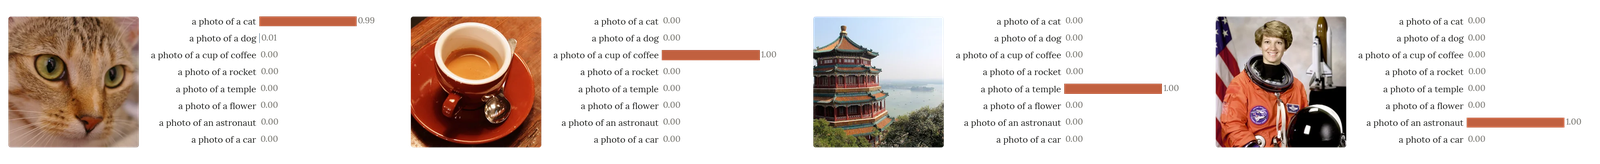

## Bẫy cài đặt

CLIP processor xử lý ảnh và chữ theo đúng checkpoint; không tự viết lại resize và chuẩn hóa pixel theo một quy tắc khác. Chuẩn hóa vector khi tự viết cosine; dùng logits của API thì cần biết model đã áp scale. Thứ tự tên lớp phải khớp thứ tự cột output. Với language model, logits tại vị trí $j$ dự đoán token kế tiếp, nên nhãn phải dịch đi một vị trí; chấm token cùng vị trí là nhìn nhầm thời điểm.



Không đưa đáp án hoặc mô tả chứa nhãn validation vào prompt rồi gọi đó là zero-shot độc lập. Không chọn ngưỡng, template hoặc tên lớp bằng hidden test. Nếu không có nhãn đánh giá nào, ta chỉ kiểm được pipeline và đọc vài mẫu, chưa đủ để kết luận chất lượng của bộ gắn nhãn ảnh cho câu lạc bộ.

**Hỏi nhanh.** Đoạn code gán tên lớp cho ảnh đầu:
```py
prompts = {"ban": "a photo of a desk",
           "may_tinh": "a photo of a computer",
           "bang": "a photo of a board"}
V = encode_text(list(prompts.values()))   # hàng: ban, may_tinh, bang
class_names = sorted(prompts)            # ['ban', 'bang', 'may_tinh']
label = class_names[int(logits[0].argmax())]
```
Ảnh đầu là một máy tính, và cột lớn nhất của `logits[0]` đúng là cột ứng với prompt máy tính. `label` là gì?

- A. `'may_tinh'`
- B. `'ban'`
- C. `'bang'`
- D. `IndexError`

<details><summary>Đáp án</summary>

C. `'bang'`

Các cột của `logits` theo thứ tự hàng của `V`: ban, may_tinh, bang. Cột máy tính là cột 1, nhưng `sorted` đã sắp tên thành ban, bang, may_tinh, nên chỉ số 1 thành `'bang'`. Không có lỗi nào được báo, chỉ có accuracy tụt âm thầm. Hãy lấy tên và prompt từ cùng một danh sách, chẳng hạn `class_names = list(prompts)`.

</details>

## Khi đi thi

- **Có asset là có baseline.** Khi đề cho sẵn CLIP hoặc một language model, chấm prompt lớp trên validation trước khi train gì: vài dòng code cho một mốc để so. Có nhãn train thì so tiếp với head-only (bài 4.2); zero-shot không mặc nhiên thắng cách học có nhãn.
- **Đọc đề xem “zero-shot” cho dùng nhãn tới đâu.** Chọn template, ngưỡng hay checkpoint bằng nhãn validation cũng là dùng nhãn. Ghi lại mọi lựa chọn đã dựa vào nhãn, và không dò chúng trên bảng điểm công khai.
- **Giữ một danh sách lớp duy nhất.** Prompt, cột logits và tên lớp trong submission lấy từ cùng một danh sách; mở vài dòng file nộp để đối chiếu với ảnh.
- **Chấm chuỗi theo một giao thức cố định.** Cùng prompt, khoảng trắng, tokenizer; chỉ chấm token ứng viên; chọn tổng hay mean log bằng validation. Nếu một nhãn thắng gần như mọi input, kiểm độ lệch nhãn bằng input trung tính.
- **Asset và thời gian theo đúng thông báo.** Chỉ dùng checkpoint và Internet theo môi trường được công bố; chuẩn bị asset trước và chạy thử offline. Text embedding của các lớp chỉ cần tính một lần rồi dùng cho mọi ảnh; phần tốn thời gian là encode ảnh theo batch.

## Tóm tắt

Zero-shot chuyển kiến thức pretraining sang nhãn mới mà không dùng ví dụ có nhãn của nhiệm vụ; few-shot đặt vài ví dụ vào prompt, fine-tuning cập nhật trọng số. CLIP so embedding ảnh và mô tả trong một không gian học chung; softmax phụ thuộc tập lớp và scale. Causal language model chấm chuỗi bằng tổng log-probability; chuẩn hóa độ dài đổi tiêu chí xếp hạng. PPL đo khả năng đoán token theo một giao thức và một tokenizer, không đo sự đúng của lời giải. Chất lượng thật của một cách zero-shot chỉ biết qua validation có nhãn.

## Kiểm tra cuối bài

**Câu 1.** Một bạn nhận xét: “GPT-2 chấm nhãn cảm xúc theo kiểu zero-shot, nghĩa là model chưa học từ dữ liệu nào.” Nhận xét này đúng hay sai?

- A. Đúng, vì zero-shot nghĩa là trọng số chưa học được gì
- B. Đúng, vì nhãn cảm xúc không xuất hiện khi pretrain
- C. Sai, vì zero-shot là dùng đúng một ví dụ có nhãn
- D. Sai, vì model đã được pretrain, chỉ là chưa có nhãn của nhiệm vụ

<details><summary>Đáp án</summary>

D. Sai, vì model đã được pretrain, chỉ là chưa có nhãn của nhiệm vụ

GPT-2 đã học từ một lượng lớn văn bản từ trước, và văn bản ấy rất có thể chứa nhiều câu khen chê. Zero-shot chỉ có nghĩa là không có ví dụ có nhãn nào của nhiệm vụ mới được dùng, cả để cập nhật trọng số lẫn để đặt vào prompt. Dùng đúng một ví dụ là one-shot, vài ví dụ là few-shot.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 243](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=87)

</details>

**Câu 2.** Câu lạc bộ đã có bộ phân loại CLIP ba lớp: bàn, bảng, máy tính. Nay cần thêm lớp “máy chiếu”, nhưng chưa có ảnh máy chiếu nào được gán nhãn. Làm thế nào là hợp lý?

- A. Thêm prompt, tính text embedding, rồi thêm một hàng vào $V$
- B. Gán nhãn ảnh máy chiếu rồi học lại head bốn lớp
- C. Fine-tune image encoder trên ảnh máy chiếu
- D. Không làm được, vì máy chiếu không phải lớp của ImageNet

<details><summary>Đáp án</summary>

A. Thêm prompt, tính text embedding, rồi thêm một hàng vào $V$

Vector của các lớp đến từ text encoder, nên thêm lớp chỉ cần thêm một mô tả và một hàng của $V$; image encoder và các lớp cũ giữ nguyên. Đó là ý nghĩa của zero-shot với CLIP. Học lại head hay fine-tune đều cần chính những ảnh có nhãn đang thiếu. CLIP học từ các cặp ảnh và chữ, không bị giới hạn trong 1000 lớp của ImageNet. Thêm lớp sẽ làm đổi softmax của các lớp cũ, nên khi có vài ảnh có nhãn thì nên dùng chúng để kiểm.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 261](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=93)

</details>

**Câu 3.** Để kiểm xem các prompt lớp có quá giống nhau không, một đội lấy `T` gồm $K$ text embedding đã chuẩn hóa từng hàng, tính `S = T @ T.T`, rồi `nearest = S.argmax(axis=1)`. Không có hai embedding nào trùng nhau. `nearest` cho ra gì?

- A. Mỗi hàng ra prompt gần nhất, khác chính nó
- B. Mỗi hàng ra chính chỉ số của nó
- C. Mỗi hàng ra prompt xa nhất của nó
- D. Báo lỗi, vì `S` không phải ma trận vuông

<details><summary>Đáp án</summary>

B. Mỗi hàng ra chính chỉ số của nó

Mỗi hàng của `T` dài 1, nên đường chéo của `S` là $\lVert\mathbf{t}_i\rVert^2 = 1$, giá trị cosine lớn nhất có thể có, còn hai vector khác nhau thì có cosine nhỏ hơn 1. Vì vậy argmax của mỗi hàng là chính nó. Phải loại đường chéo trước, chẳng hạn bằng `np.fill_diagonal(S, -np.inf)`. Cosine lớn nghĩa là gần, không phải xa. `S` có shape `(K, K)` nên luôn vuông.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.8–5.9](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=13)

</details>

**Câu 4.** Một ảnh có cosine 0.30 với mô tả “bàn” và 0.25 với mô tả “bảng”. Softmax hai lớp cho “bàn” bằng bao nhiêu khi temperature $\tau = 1$, tức scale 1, và khi $\tau = 0.01$, tức scale 100?

- A. Với $\tau = 1$ khoảng 0.99, với $\tau = 0.01$ khoảng 0.51
- B. Với $\tau = 1$ khoảng 0.55, với $\tau = 0.01$ khoảng 0.55
- C. Với $\tau = 1$ khoảng 0.51, với $\tau = 0.01$ khoảng 0.51
- D. Với $\tau = 1$ khoảng 0.51, với $\tau = 0.01$ khoảng 0.99

<details><summary>Đáp án</summary>

D. Với $\tau = 1$ khoảng 0.51, với $\tau = 0.01$ khoảng 0.99

Với hai lớp, softmax của lớp đầu là $1/(1 + e^{-s\,\Delta})$, với $\Delta = 0.05$. Scale 1 cho $1/(1 + e^{-0.05}) \approx 0.51$, gần như chia đều. Scale 100 cho $1/(1 + e^{-5}) \approx 0.99$. Temperature nhỏ làm phân phối nhọn, temperature lớn làm nó phẳng, còn argmax vẫn là “bàn” ở cả hai trường hợp. 0.55 là chia thẳng $0.30/(0.30 + 0.25)$, không qua hàm mũ. Đây là lý do CLIP cần học một scale lớn: cosine của các mô tả có thể rất sát nhau, và không có scale thì xác suất gần như không phân biệt được các lớp.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 240](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=86)

</details>

**Câu 5.** Để phân loại review, một đội đặt bốn review có nhãn vào đầu prompt, rồi để GPT-2 chấm nhãn cho review mới. Không có optimizer nào được chạy. Cách này gọi là gì, và trọng số của model ra sao?

- A. Zero-shot, trọng số giữ nguyên
- B. Few-shot, trọng số thay đổi theo bốn ví dụ
- C. Few-shot, trọng số giữ nguyên
- D. Fine-tuning, bốn ví dụ là một batch train

<details><summary>Đáp án</summary>

C. Few-shot, trọng số giữ nguyên

Bốn ví dụ có nhãn nằm trong prompt, nên đây là few-shot, hay in-context learning, không còn là zero-shot. Không có backward và optimizer nên trọng số giữ nguyên; forward không làm đổi tham số. Fine-tuning mới dùng ví dụ để cập nhật trọng số. Vì đã dùng nhãn của nhiệm vụ, kết quả phải được báo là few-shot.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 244](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=88)

</details>

**Câu 6.** Chấm cảm xúc bằng GPT-2: điểm của mỗi nhãn là log-prob của “ positive” hoặc “ negative” đứng sau review và chữ “Sentiment:”, mỗi nhãn đúng một token. Trên 200 review validation gồm 100 khen, 100 chê, model chọn positive tới 186 lần, và accuracy là 0.54. Bước tiếp theo hợp lý nhất là gì?

- A. Chấm hai nhãn với một input trung tính để đo độ lệch
- B. Đổi sang trung bình log, vì tổng log phạt nhãn dài
- C. Báo 0.54 là mức trần của cách zero-shot này
- D. Đưa 200 review validation vào prompt làm ví dụ

<details><summary>Đáp án</summary>

A. Chấm hai nhãn với một input trung tính để đo độ lệch

Chọn một nhãn cho gần như mọi input là dấu hiệu điểm số đang mang độ lệch sẵn có của nhãn, chứ không chỉ phản ánh nội dung review. Chấm hai nhãn với một input trung tính sẽ đo được độ lệch ấy; trừ đi điểm nền rồi kiểm lại trên validation. Mỗi nhãn chỉ có một token, nên tổng và trung bình log bằng nhau, đổi tiêu chí chẳng thay đổi gì. 0.54 chỉ là điểm của một cách làm, chưa phải mức trần. Đưa review validation vào prompt là dùng chính dữ liệu đánh giá làm ví dụ, nên điểm trên tập ấy không còn khách quan.

</details>

**Câu 7.** Hai token được chấm có xác suất có điều kiện là $1/2$ và $1/8$. PPL, tính bằng exp của trung bình âm log-probability, bằng bao nhiêu?

- A. $1/4$
- B. 4
- C. 3.2
- D. 16

<details><summary>Đáp án</summary>

B. 4

$\text{PPL} = \exp[-(\log\tfrac12 + \log\tfrac18)/2] = \sqrt{2\cdot 8} = 4$, là nghịch đảo của trung bình nhân $\sqrt{1/16} = 1/4$. 1/4 là chính trung bình nhân, quên lấy nghịch đảo. 3.2 là nghịch đảo của trung bình cộng $5/16$. 16 là nghịch đảo xác suất của cả chuỗi, quên lấy căn bậc hai.

</details>

**Câu 8.** Nhật ký train một language model ghi train loss 1.8, là trung bình negative log-likelihood theo token với log tự nhiên, và validation perplexity 19.1, cùng tokenizer và cùng cách đếm token. Trung bình negative log-likelihood trên validation khoảng bao nhiêu?

- A. Khoảng 1.28, thấp hơn train loss
- B. Khoảng 2.95, cao hơn train loss
- C. Khoảng 6.05, cao hơn train loss
- D. 19.1, vì PPL chính là loss trung bình

<details><summary>Đáp án</summary>

B. Khoảng 2.95, cao hơn train loss

PPL là exp của trung bình negative log-likelihood, nên loss trên validation là $\ln 19.1 \approx 2.95$, cao hơn 1.8, tức có khoảng cách giữa train và validation. 1.28 là $\log_{10} 19.1$, sai cơ số. 6.05 là $e^{1.8}$, tức PPL của train, không phải loss trên validation.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 84](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=34)

</details>

**Câu 9.** Causal LM nhận input [BOS, A, B]. Nếu chuỗi đầy đủ là [BOS, A, B, EOS], thì khi train theo kiểu đoán token kế tiếp, logits ở ba vị trí được so với những target nào?

- A. [BOS, A, B]
- B. [B, EOS, PAD]
- C. [EOS, B, A]
- D. [A, B, EOS]

<details><summary>Đáp án</summary>

D. [A, B, EOS]

Logits ở vị trí $j$ dự đoán token ở vị trí $j + 1$: BOS đoán A, A đoán B, B đoán EOS, nên target là chuỗi dịch sang trái một vị trí. [BOS, A, B] là học chép lại chính token đang đọc. [B, EOS, PAD] là lệch hai vị trí. [EOS, B, A] là đảo thứ tự.

</details>

**Câu 10.** Bài thi có 10 000 ảnh test và 50 lớp. Code của một đội chạy text encoder trên cả 50 prompt lớp ở bên trong vòng lặp qua từng ảnh. Chuyển phần encode prompt ra ngoài vòng lặp thì số prompt mà text encoder phải xử lý giảm từ bao nhiêu xuống bao nhiêu, và dự đoán có đổi không?

- A. Từ 500 000 xuống 50, và dự đoán giữ nguyên
- B. Từ 500 000 xuống 50, và dự đoán thay đổi theo
- C. Từ 10 000 xuống 50, và dự đoán giữ nguyên
- D. Từ 10 000 xuống 1, và dự đoán giữ nguyên

<details><summary>Đáp án</summary>

A. Từ 500 000 xuống 50, và dự đoán giữ nguyên

Trong vòng lặp có $10\,000\times 50 = 500\,000$ lượt encode prompt, còn ngoài vòng lặp chỉ có 50. Ma trận $V$ không phụ thuộc vào ảnh, và model ở chế độ eval cho cùng một vector mỗi lần, nên dự đoán giống hệt nhau. 10 000 là số ảnh chứ không phải số prompt. Mỗi lớp cần một vector riêng, nên không thể chỉ còn 1. Phần còn lại của ngân sách là encode ảnh theo batch.

</details>

## Đọc thêm

- Radford và cộng sự — [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020): nguồn gốc CLIP, contrastive learning và cách dùng text làm classifier.
- [Transformers — CLIP](https://huggingface.co/docs/transformers/model_doc/clip): shape của embedding/logits và cách gọi model cùng processor.
- [CLIP model card](https://huggingface.co/openai/clip-vit-base-patch32): xem miền dùng, giới hạn và điều kiện đánh giá trước khi chọn asset.
- [Transformers — perplexity of fixed-length models](https://huggingface.co/docs/transformers/perplexity): tokenization, context window và cách đếm token được chấm.
- [GPT-2 model card](https://huggingface.co/openai-community/gpt2): xem model causal, ngôn ngữ và giới hạn dùng để chấm chuỗi.
- Zhao và cộng sự — [Calibrate Before Use: Improving Few-Shot Performance of Language Models](https://arxiv.org/abs/2102.09690): độ lệch nhãn khi chấm bằng prompt và cách hiệu chỉnh bằng input trung tính.

Nguồn ảnh: ảnh tháp và ảnh hoa là ảnh mẫu `china.jpg` (danielbuechele, Flickr, CC BY 2.0) và `flower.jpg` (vultilion, Flickr, CC BY 2.0) kèm scikit-learn; ảnh chữ số lấy từ bộ `load_digits` của scikit-learn; ảnh `chelsea`, `coffee`, `rocket`, `astronaut` kèm scikit-image (CC0 hoặc public domain).